# Ein Münzbild auswerten

Wir wenden das trainierte YOLO26n-Modell auf ein eigenes Foto an, das **nicht aus dem Datensatz** stammt:

1. Münzen erkennen und die Detektionen als Tabelle ausgeben
2. Ergebnis visualisieren
3. Münzen je Klasse zählen und den Betrag berechnen
4. Einfluss des Schwellenwerts `conf` auf den Betrag untersuchen
5. Mit den tatsächlich vorhandenen Münzen vergleichen

## Umgebung

Das Modell stammt aus `LösungYoloTraining.ipynb`. Das Bild `testbild.jpg` liegt im Ordner des Notebooks.

In [1]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
from ultralytics import YOLO

MODEL_PATH = "runs/detect/muenzen/weights/best.pt"
IMAGE_PATH = "testbild.jpg"

# Wert jeder Klasse in Euro, Reihenfolge wie in data.yaml
VALUES = {"1ct": 0.01, "2ct": 0.02, "5ct": 0.05, "10ct": 0.10,
          "20ct": 0.20, "50ct": 0.50, "1eur": 1.00, "2eur": 2.00}

model = YOLO(MODEL_PATH)
print(model.names)

{0: '1ct', 1: '2ct', 2: '5ct', 3: '10ct', 4: '20ct', 5: '50ct', 6: '1eur', 7: '2eur'}


## Das Originalbild

Bildgröße: 4080 x 3072 Pixel


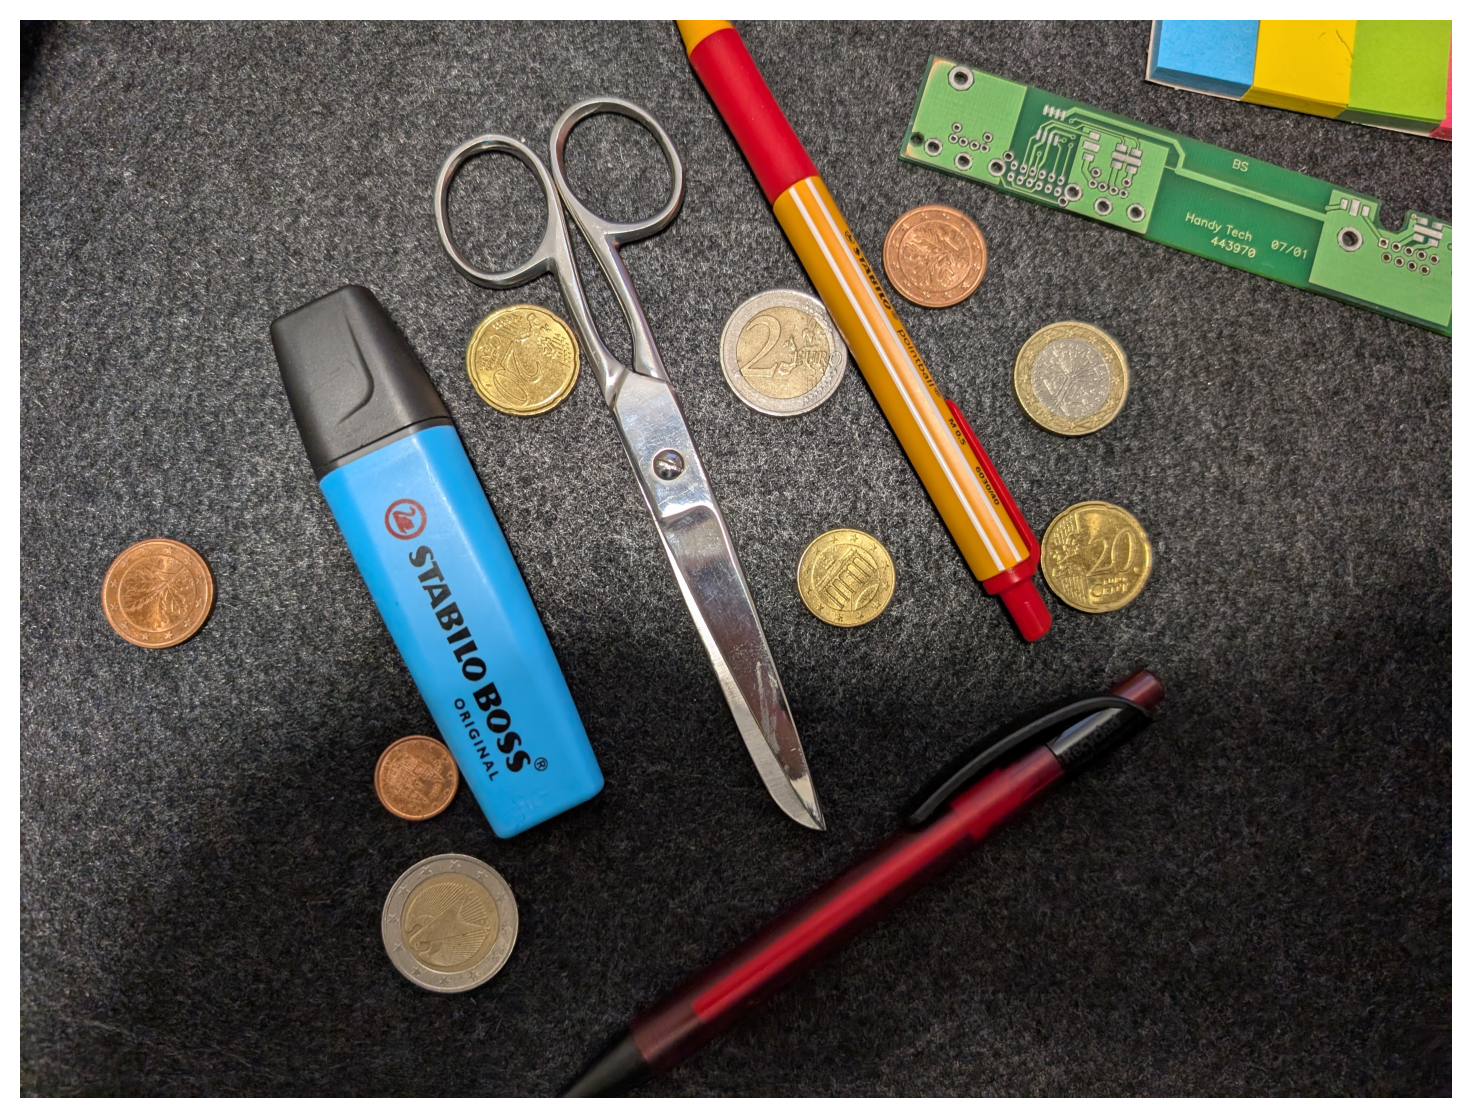

In [2]:
image_bgr = cv2.imread(IMAGE_PATH)
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
print("Bildgröße:", image_rgb.shape[1], "x", image_rgb.shape[0], "Pixel")

plt.figure(figsize=(10, 7))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

## 1. Münzen erkennen

YOLO skaliert das Bild intern auf die Trainingsgröße, hier $960 \times 960$ Pixel. Die Boxen werden wieder in Originalkoordinaten zurückgerechnet.

In [3]:
CONF = 0.5     # Schwellenwert für die Confidence
IOU = 0.5      # IoU-Schwelle für NMS

# agnostic_nms=True: NMS über alle Klassen, damit jede Münze höchstens eine Box erhält
r = model.predict(IMAGE_PATH, conf=CONF, iou=IOU, agnostic_nms=True, verbose=False)[0]
boxes = r.boxes.cpu().numpy()      # Tensoren ggf. von der GPU holen

detections = pd.DataFrame({
    "Klasse": [r.names[int(c)] for c in boxes.cls],
    "Wert in €": [VALUES[r.names[int(c)]] for c in boxes.cls],
    "Confidence": boxes.conf.round(2),
    "x1": boxes.xyxy[:, 0].round(), "y1": boxes.xyxy[:, 1].round(),
    "x2": boxes.xyxy[:, 2].round(), "y2": boxes.xyxy[:, 3].round(),
}).sort_values("x1").reset_index(drop=True)
detections

,Klasse,Wert in €,Confidence,x1,y1,x2,y2
0,5ct,0.05,0.68,230.0,1477.0,551.0,1792.0
1,1ct,0.01,0.67,1009.0,2036.0,1249.0,2283.0
2,2eur,2.00,0.94,1027.0,2376.0,1426.0,2777.0
3,20ct,0.20,0.73,1270.0,818.0,1593.0,1122.0
4,2eur,2.00,0.88,1992.0,762.0,2367.0,1129.0
5,10ct,0.10,0.74,2214.0,1448.0,2497.0,1731.0
6,2ct,0.02,0.80,2458.0,527.0,2756.0,820.0
7,1eur,1.00,0.72,2832.0,855.0,3159.0,1186.0
8,20ct,0.20,0.75,2907.0,1372.0,3225.0,1691.0


## 2. Ergebnis visualisieren

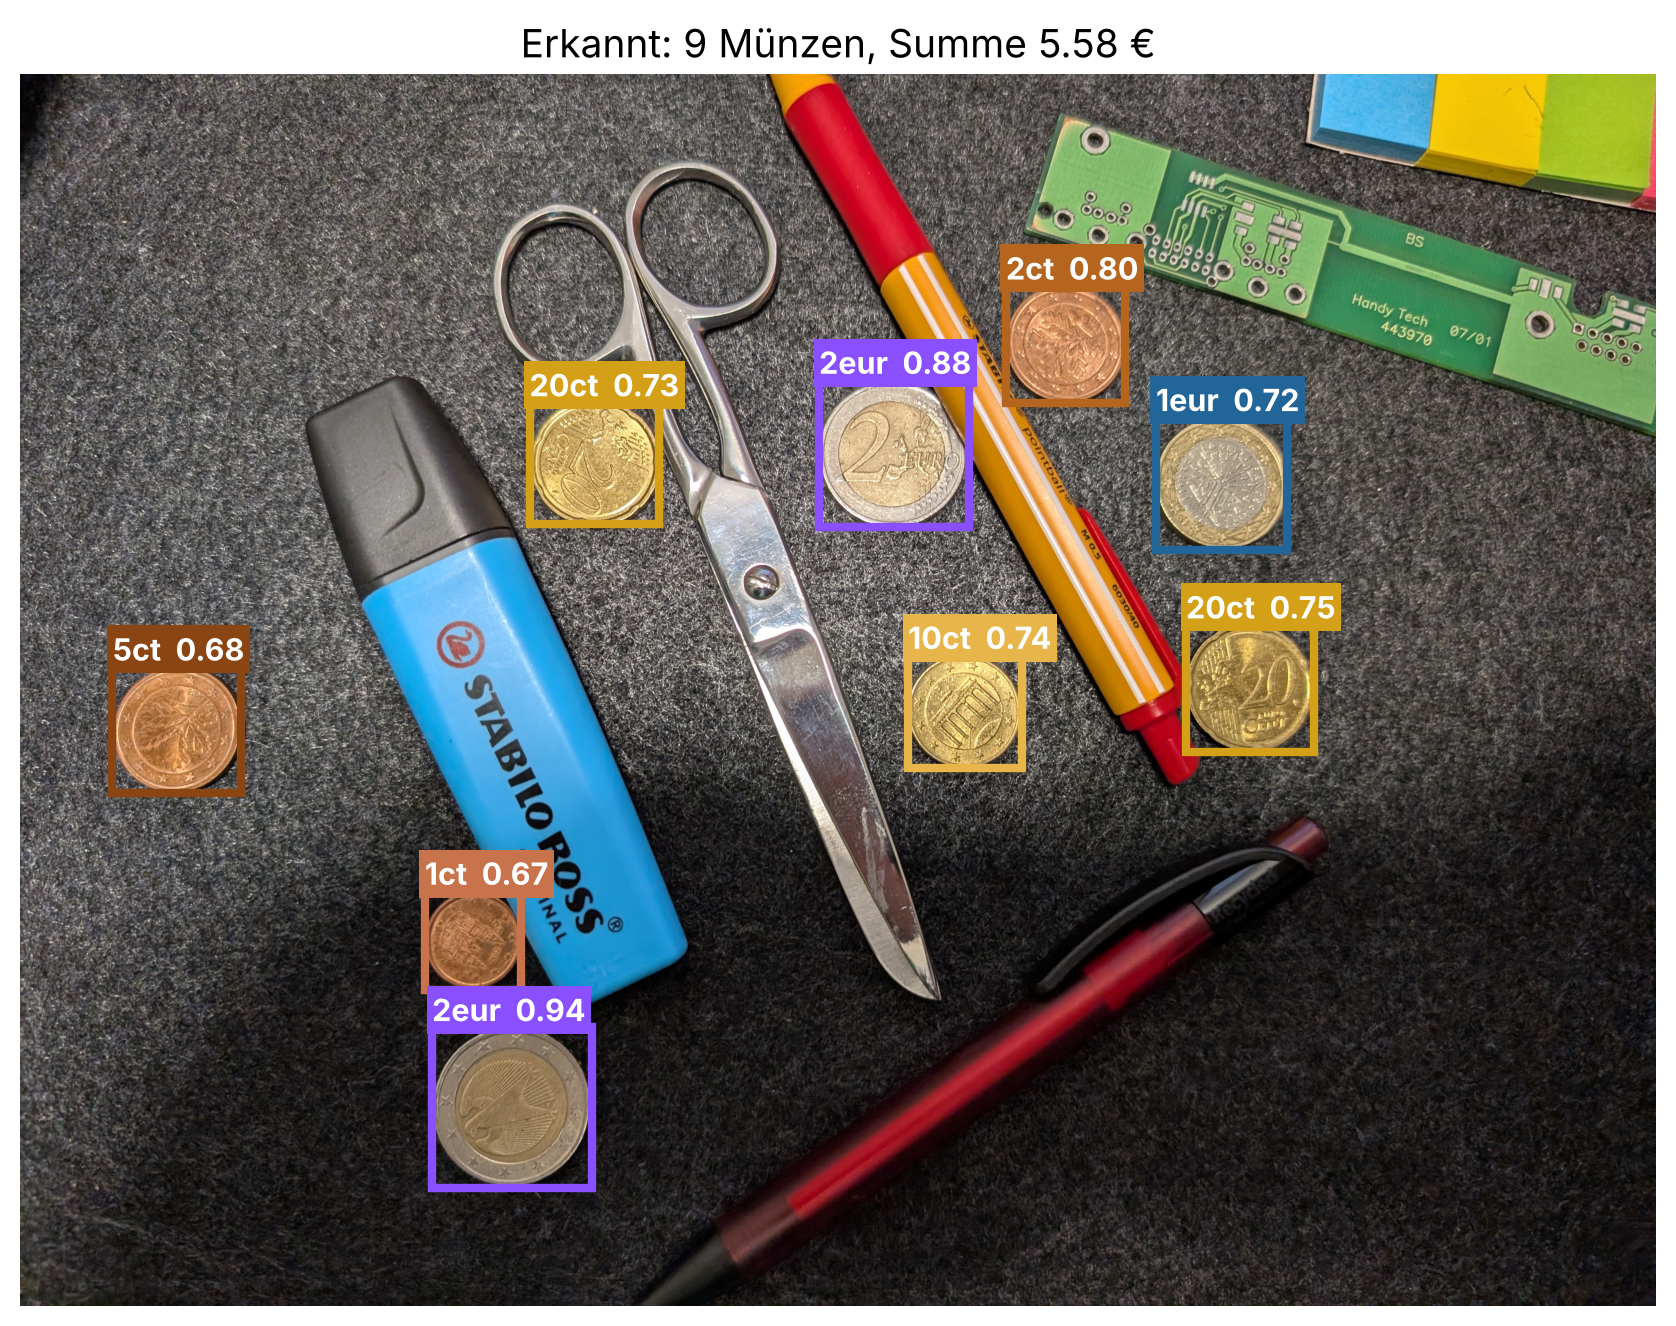

In [4]:
COLORS = {"1ct": "#C8734B", "2ct": "#B5651D", "5ct": "#8B4513", "10ct": "#E8B54A",
          "20ct": "#D4A017", "50ct": "#B8860B", "1eur": "#226699", "2eur": "#8A4FFF"}

total = detections["Wert in €"].sum()

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image_rgb)
for _, d in detections.iterrows():
    color = COLORS[d["Klasse"]]
    ax.add_patch(patches.Rectangle((d.x1, d.y1), d.x2 - d.x1, d.y2 - d.y1,
                                   fill=False, lw=3, ec=color))
    ax.text(d.x1, d.y1 - 15, f"{d['Klasse']}  {d['Confidence']:.2f}",
            color="white", fontsize=11, weight="bold",
            bbox=dict(facecolor=color, edgecolor="none", pad=2))
ax.set_title(f"Erkannt: {len(detections)} Münzen, Summe {total:.2f} €", fontsize=14)
ax.axis("off")
plt.show()

## 3. Münzen zählen und Betrag berechnen

In [5]:
summary = (detections.groupby("Klasse")
           .agg(Anzahl=("Klasse", "size"), Wert=("Wert in €", "first"))
           .reindex([k for k in VALUES if k in set(detections["Klasse"])]))
summary["Summe in €"] = summary["Anzahl"] * summary["Wert"]
summary.loc["Gesamt"] = [summary["Anzahl"].sum(), None, summary["Summe in €"].sum()]
summary

,Anzahl,Wert,Summe in €
Klasse,,,
1ct,1.0,0.01,0.01
2ct,1.0,0.02,0.02
5ct,1.0,0.05,0.05
10ct,1.0,0.10,0.10
20ct,2.0,0.20,0.40
1eur,1.0,1.00,1.00
2eur,2.0,2.00,4.00
Gesamt,9.0,NaN,5.58


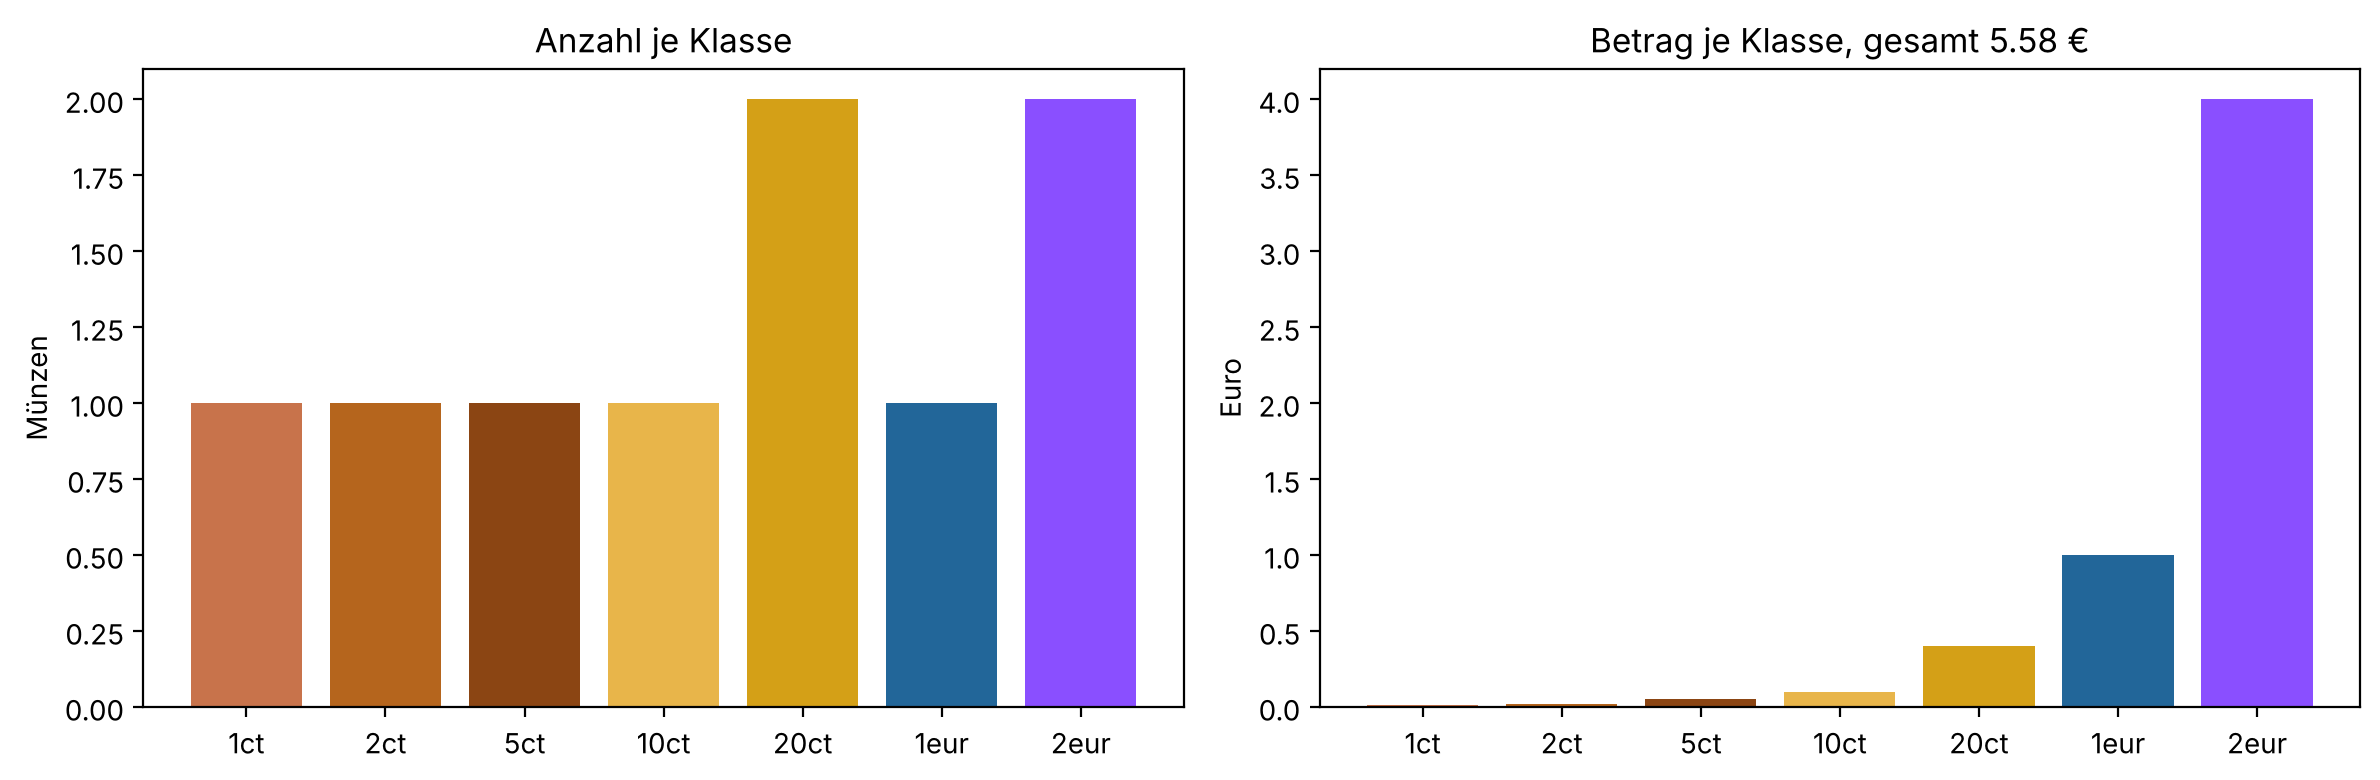

In [6]:
per_class = summary.drop("Gesamt")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(per_class.index, per_class["Anzahl"], color=[COLORS[k] for k in per_class.index])
ax[0].set_title("Anzahl je Klasse")
ax[0].set_ylabel("Münzen")
ax[1].bar(per_class.index, per_class["Summe in €"], color=[COLORS[k] for k in per_class.index])
ax[1].set_title(f"Betrag je Klasse, gesamt {total:.2f} €")
ax[1].set_ylabel("Euro")
plt.tight_layout()
plt.show()

## 4. Einfluss des Schwellenwerts `conf`

Ein niedriger Schwellenwert findet mehr Münzen, erzeugt aber auch mehr Fehlalarme. Beides verändert den Betrag.

In [7]:
rows = []
for conf in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    res = model.predict(IMAGE_PATH, conf=conf, iou=IOU, agnostic_nms=True, verbose=False)[0]
    names = [res.names[int(c)] for c in res.boxes.cls]
    rows.append({"conf": conf, "Münzen": len(names),
                 "Summe in €": round(sum(VALUES[n] for n in names), 2),
                 "Klassen": ", ".join(sorted(names, key=list(VALUES).index))})
by_conf = pd.DataFrame(rows)
by_conf

,conf,Münzen,Summe in €,Klassen
0,0.1,9,5.58,"1ct, 2ct, 5ct, 10ct, 20ct, 20ct, 1eur, 2eur, 2eur"
1,0.2,9,5.58,"1ct, 2ct, 5ct, 10ct, 20ct, 20ct, 1eur, 2eur, 2eur"
2,0.3,9,5.58,"1ct, 2ct, 5ct, 10ct, 20ct, 20ct, 1eur, 2eur, 2eur"
3,0.4,9,5.58,"1ct, 2ct, 5ct, 10ct, 20ct, 20ct, 1eur, 2eur, 2eur"
4,0.5,9,5.58,"1ct, 2ct, 5ct, 10ct, 20ct, 20ct, 1eur, 2eur, 2eur"
5,0.6,9,5.58,"1ct, 2ct, 5ct, 10ct, 20ct, 20ct, 1eur, 2eur, 2eur"
6,0.7,7,5.52,"2ct, 10ct, 20ct, 20ct, 1eur, 2eur, 2eur"
7,0.8,2,4.00,"2eur, 2eur"


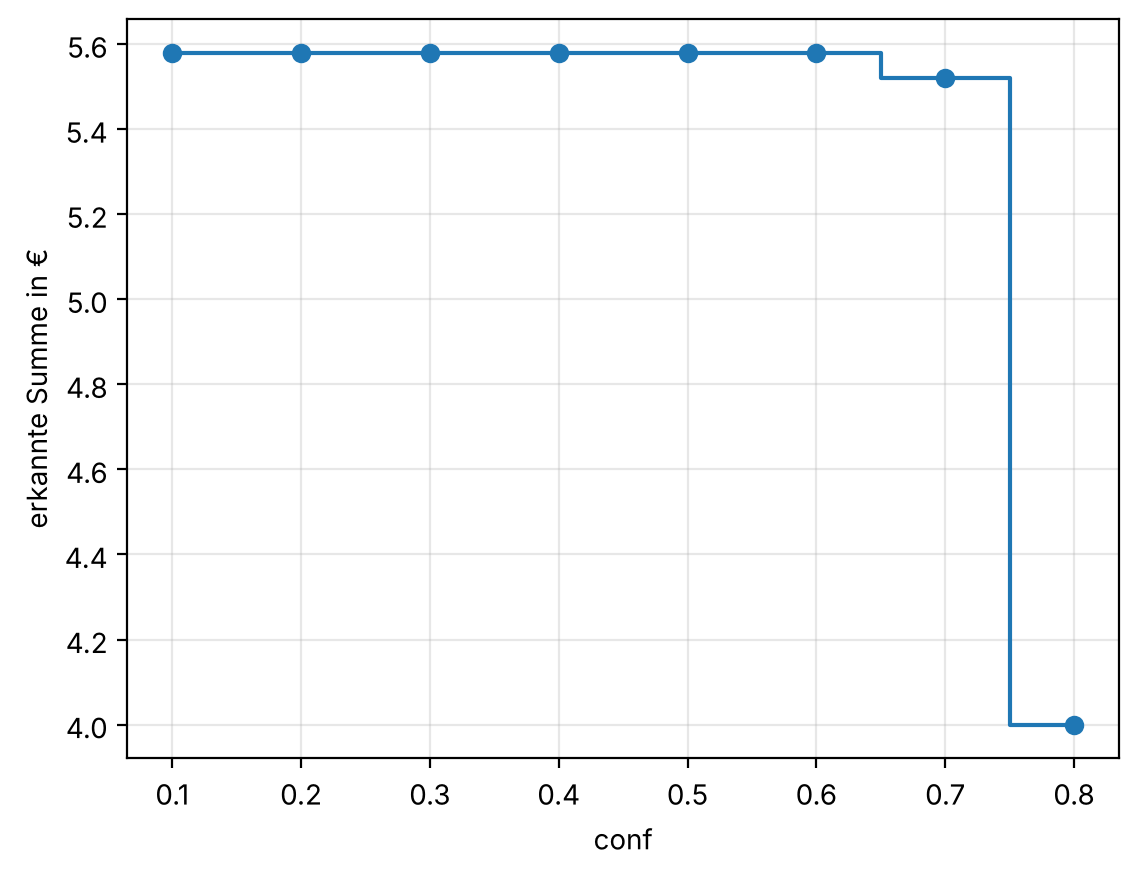

In [8]:
plt.step(by_conf["conf"], by_conf["Summe in €"], where="mid", marker="o")
plt.xlabel("conf")
plt.ylabel("erkannte Summe in €")
plt.grid(alpha=0.3)
plt.show()

## 5. Vergleich mit den tatsächlichen Münzen

Auf dem Foto liegen neun Münzen: zwei 2-€-Münzen, eine 1-€-Münze, zwei 20-ct-Münzen, eine 10-ct-Münze, zwei 5-ct-Münzen und eine 1-ct-Münze, zusammen **5,61 €**. Dazu kommen Gegenstände, die keine Münzen sind: Schere, Stifte, Textmarker, Haftnotizen und eine Platine. Das Foto gehört zu keinem Split des Datensatzes.

In [9]:
TRUE_COINS = 2 * ["2eur"] + ["1eur"] + 2 * ["20ct"] + ["10ct"] + 2 * ["5ct"] + ["1ct"]

true_total = sum(VALUES[k] for k in TRUE_COINS)
true_counts = pd.Series(TRUE_COINS).value_counts()
found_counts = detections["Klasse"].value_counts()

comparison = pd.DataFrame({"tatsächlich": true_counts, "erkannt": found_counts}).fillna(0).astype(int)
comparison = comparison.reindex([k for k in VALUES if k in comparison.index])
comparison["Differenz"] = comparison["erkannt"] - comparison["tatsächlich"]
print(f"Tatsächlich: {true_total:.2f} €, erkannt: {total:.2f} €, Fehler: {total - true_total:+.2f} €")
comparison

Tatsächlich: 5.61 €, erkannt: 5.58 €, Fehler: -0.03 €


,tatsächlich,erkannt,Differenz
1ct,1,1,0
2ct,0,1,1
5ct,2,1,-1
10ct,1,1,0
20ct,2,2,0
1eur,1,1,0
2eur,2,2,0
